In [5]:
import numpy as np
import hashlib
import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import multivariate_normal
from sklearn.preprocessing import StandardScaler
from gmm import MyGMM

# seed based on username
username = "konda.rithvika"
seed = int(hashlib.sha256(username.encode()).hexdigest(), 16) % (2**32)
print("Seed:", seed)


Seed: 2226785795


In [6]:
data = pd.read_csv("Clustering_dataset.csv")

# Drop CustomerID
if "CustomerID" in data.columns:
    data = data.drop(columns=["CustomerID"])

# Encode Genre
if "Genre" in data.columns:
    data["Genre"] = data["Genre"].fillna(data["Genre"].mode()[0])
    data["Genre"] = data["Genre"].map({"Male": 0, "Female": 1})

# Fill missing numeric columns
for col in data.columns:
    data[col] = data[col].fillna(data[col].median())

# Scaling
scaler = StandardScaler()
X = scaler.fit_transform(data.values)

print("Dataset shape:", X.shape)


Dataset shape: (200, 4)


Membership matrix shape: (200, 5)
Overall log-likelihood: 297.14098211689696


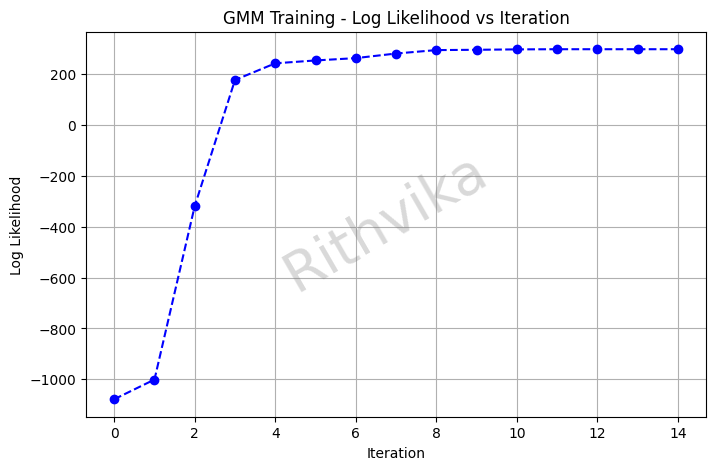

In [7]:
# Fit custom GMM
gmm = MyGMM(k=5, max_iter=100, random_state=seed,reg_covar=1e-6)
gmm.fit(X)

memberships = gmm.getMembership()
print("Membership matrix shape:", memberships.shape)
print("Overall log-likelihood:", gmm.getLikelihood(X))

gmm.drawLikelihood()


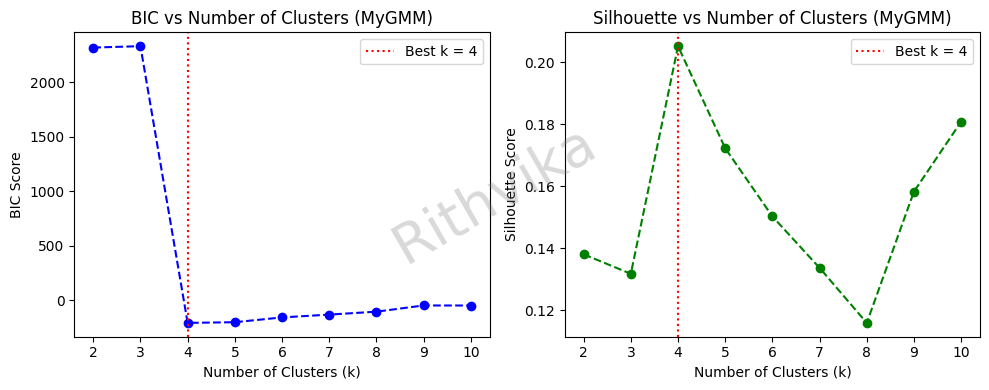

Optimal k according to BIC = 4
Optimal k according to Silhouette = 4


In [8]:
from sklearn.metrics import silhouette_score

K_range = range(2, 11)
bic_scores = []
silhouette_scores = []

n_samples, n_features = X.shape

for k in K_range:
    gm = MyGMM(k=k, max_iter=100, reg_covar=1e-6, random_state=seed)
    gm.fit(X)
    ll = gm.getLikelihood(X)

    num_params = (k - 1) + k * n_features + k * n_features * (n_features + 1) / 2
    bic = -2 * ll + num_params * np.log(n_samples)
    bic_scores.append(bic)

    labels = np.argmax(gm.getMembership(), axis=1)
    silhouette_scores.append(silhouette_score(X, labels))

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(list(K_range), bic_scores, marker="o", linestyle="--", color="b")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("BIC Score")
plt.title("BIC vs Number of Clusters (MyGMM)")
best_k_bic = K_range[np.argmin(bic_scores)]
plt.axvline(x=best_k_bic, color="r", linestyle=":", label=f"Best k = {best_k_bic}")
plt.legend()

plt.subplot(1,2,2)
plt.plot(list(K_range), silhouette_scores, marker="o", linestyle="--", color="g")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette vs Number of Clusters (MyGMM)")
best_k_sil = K_range[np.argmax(silhouette_scores)]
plt.axvline(x=best_k_sil, color="r", linestyle=":", label=f"Best k = {best_k_sil}")
plt.legend()

plt.tight_layout()
plt.text(0.5, 0.5, 'Rithvika',
         transform=plt.gcf().transFigure,
         fontsize=40, color='gray', alpha=0.3,
         ha='center', va='center', rotation=30)
plt.show()

print(f"Optimal k according to BIC = {best_k_bic}")
print(f"Optimal k according to Silhouette = {best_k_sil}")
